# Linux 지원 Steam 게임 추천: 초기 A·B·C 데이터 분석

- **A (학습)**: Game Recommendations on Steam (`antonkozyriev/game-recommendations-on-steam`)
- **B (외부 테스트)**: Steam Video Game and Bundle Data (`pypiahmad/steam-video-game-and-bundle-data`, UCSD McAuley 데이터 복제본)
- **C (보조 메타데이터)**: Steam Games Dataset 2025 (`artermiloff/steam-games-dataset`, `games_march2025_cleaned.csv`)

재현 순서 (EDA/ 폴더 기준)
1. `python -I scripts/download_data.py` — Kaggle 공개 파일 다운로드 + `data/raw/manifest.json`(버전·크기·SHA256)
2. `python -I scripts/preprocess.py` — 원본 → `data/processed/*.parquet` (형식 변환만, 행 삭제 없음)
3. `python scripts/build_notebook.py` — 이 노트북 생성·실행

이 노트북은 Kieran·frank 선택 이전의 분석이다. 현재 결과는 `../reports/forgemaster_model_evaluation.md`, 용어 설명은 `../docs/terminology.md`에 있다.

이 노트북의 모든 수치는 실제 계산값이며 `reports/eda_metrics.json`, `reports/tables/*.csv`에 저장된다.
서로 다른 데이터셋의 사용자 ID는 동일 인물로 가정하지 않는다(게임 App ID만 결합).

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

EDA = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
P, FIG, REP = EDA / "data" / "processed", EDA / "figures", EDA / "reports"
TAB = REP / "tables"
for d in (FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

RESULTS = {}


def _py(v):
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.floating,)):
        return float(v)
    if isinstance(v, (np.bool_,)):
        return bool(v)
    if isinstance(v, pd.Timestamp):
        return v.isoformat()
    if isinstance(v, dict):
        return {k: _py(x) for k, x in v.items()}
    if isinstance(v, (list, tuple)):
        return [_py(x) for x in v]
    return v


def rec(key, value):
    """계산된 수치를 RESULTS에 기록하고 그대로 반환."""
    RESULTS[key] = _py(value)
    return value


def save_table(df, name, index=False):
    df.to_csv(TAB / f"{name}.csv", index=index, encoding="utf-8-sig")
    return df


# 차트 스타일: 범주형 색상은 고정 순서(파랑 → 주황 → 청록), 얇은 마크, 연한 그리드.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW]),
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "legend.frameon": False,
})


def save_fig(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")


def ccdf(ax, counts, label, color=None):
    """P(count >= x) 를 log-log 계단선으로."""
    v = np.sort(np.asarray(counts))
    x, idx = np.unique(v, return_index=True)
    y = 1 - idx / len(v)
    ax.step(x, y, where="post", label=label, color=color)
    ax.set_xscale("log")
    ax.set_yscale("log")


def qtable(s, qs=(0.25, 0.5, 0.75, 0.9, 0.99)):
    return {f"p{int(q * 100)}": float(s.quantile(q)) for q in qs} | {"mean": float(s.mean()), "max": float(s.max())}

## 0. 데이터 출처·버전·용량과 다운로드 기록

In [2]:
manifest = json.loads((EDA / "data" / "raw" / "manifest.json").read_text("utf-8"))
src_rows = []
for k, v in manifest.items():
    for f in v["files"]:
        src_rows.append({"dataset": k, "kaggle_ref": v["ref"], "kaggle_version": v["kaggle_version"],
                         "kaggle_last_updated": v["kaggle_last_updated"][:10], "license": v["license"],
                         "file": f["kaggle_file"], "MB": round(f["local_bytes"] / 1e6, 1),
                         "partial_download": bool(f["partial_head_bytes"]), "downloaded_at": v["downloaded_at_utc"][:10]})
sources = save_table(pd.DataFrame(src_rows).sort_values(["dataset", "file"]), "00_sources")
sources

,dataset,kaggle_ref,kaggle_version,kaggle_last_updated,license,file,MB,partial_download,downloaded_at
6,A,antonkozyriev/game-recommendations-on-steam,28,2024-08-14,CC0: Public Domain,games.csv,4.9000,False,2026-11-03
7,A,antonkozyriev/game-recommendations-on-steam,28,2024-08-14,CC0: Public Domain,games_metadata.json,17.5000,False,2026-11-03
9,A,antonkozyriev/game-recommendations-on-steam,28,2024-08-14,CC0: Public Domain,recommendations.csv,"2,023.2000",False,2026-11-03
8,A,antonkozyriev/game-recommendations-on-steam,28,2024-08-14,CC0: Public Domain,users.csv,193.1000,False,2026-11-03
0,B,pypiahmad/steam-video-game-and-bundle-data,1,2023-10-29,Apache 2.0,australian_user_reviews.json,26.3000,False,2026-11-03
1,B,pypiahmad/steam-video-game-and-bundle-data,1,2023-10-29,Apache 2.0,australian_users_items.json,553.1000,False,2026-11-03
3,B,pypiahmad/steam-video-game-and-bundle-data,1,2023-10-29,Apache 2.0,bundle_data.json,0.8000,False,2026-11-03
2,B,pypiahmad/steam-video-game-and-bundle-data,1,2023-10-29,Apache 2.0,steam_games.json,21.2000,False,2026-11-03
4,B,pypiahmad/steam-video-game-and-bundle-data,1,2023-10-29,Apache 2.0,steam_reviews.json/steam_new.json,67.1000,True,2026-11-03
5,C,artermiloff/steam-games-dataset,2,2025-03-13,MIT,games_march2025_cleaned.csv,468.6000,False,2026-11-03


## 1. 데이터 구조: 행 수, 열, 자료형, 결측, 중복

In [3]:
A_rec = pd.read_parquet(P / "A_recommendations.parquet")
A_games = pd.read_parquet(P / "A_games.parquet")
A_users = pd.read_parquet(P / "A_users.parquet")
A_meta = pd.read_parquet(P / "A_games_metadata.parquet")
B_prof = pd.read_parquet(P / "B_users_items_profiles.parquet")
B_items = pd.read_parquet(P / "B_users_items.parquet")
B_rev = pd.read_parquet(P / "B_reviews.parquet")
B_sg = pd.read_parquet(P / "B_steam_games.parquet")
B_bun = pd.read_parquet(P / "B_bundle_items.parquet")
C = pd.read_parquet(P / "C_games_2025.parquet")

tables = {"A_recommendations": A_rec, "A_games": A_games, "A_users": A_users, "A_games_metadata": A_meta,
          "B_users_items(profile)": B_prof, "B_users_items(long)": B_items, "B_reviews(long)": B_rev,
          "B_steam_games": B_sg, "B_bundle_items(long)": B_bun, "C_games_2025": C}

schema = pd.concat([
    pd.DataFrame({"table": n, "column": df.columns, "dtype": df.dtypes.astype(str).values,
                  "n_null": df.isna().sum().values, "null_pct": (df.isna().mean() * 100).round(3).values})
    for n, df in tables.items()])
save_table(schema, "01_schema_nulls")
schema[schema.n_null > 0]

,table,column,dtype,n_null,null_pct
11,B_reviews(long),posted_date,datetime64[us],10119,17.0630
0,B_steam_games,id_raw,str,2,0.0060
1,B_steam_games,app_name,str,2,0.0060
2,B_steam_games,title,str,2050,6.3790
3,B_steam_games,release_date,str,2067,6.4320
4,B_steam_games,genres,object,3283,10.2160
5,B_steam_games,tags,object,163,0.5070
6,B_steam_games,specs,object,670,2.0850
7,B_steam_games,price,str,1377,4.2850
9,B_steam_games,developer,str,3299,10.2660


In [4]:
def n_dup(df, cols):
    return int(df.duplicated(cols).sum())


structure = pd.DataFrame([
    dict(table="A_recommendations", rows=len(A_rec), cols=A_rec.shape[1], users=A_rec.user_id.nunique(),
         items=A_rec.app_id.nunique(), dup_key="user_id+app_id", dup_rows=n_dup(A_rec, ["user_id", "app_id"]),
         date_min=A_rec.date.min(), date_max=A_rec.date.max()),
    dict(table="A_games", rows=len(A_games), cols=A_games.shape[1], items=A_games.app_id.nunique(),
         dup_key="app_id", dup_rows=n_dup(A_games, ["app_id"]),
         date_min=A_games.date_release.min(), date_max=A_games.date_release.max()),
    dict(table="A_users", rows=len(A_users), cols=A_users.shape[1], users=A_users.user_id.nunique(),
         dup_key="user_id", dup_rows=n_dup(A_users, ["user_id"])),
    dict(table="A_games_metadata", rows=len(A_meta), cols=A_meta.shape[1], items=A_meta.app_id.nunique(),
         dup_key="app_id", dup_rows=n_dup(A_meta, ["app_id"])),
    dict(table="B_users_items(profile)", rows=len(B_prof), cols=B_prof.shape[1], users=B_prof.user_id.nunique(),
         dup_key="user_id", dup_rows=n_dup(B_prof, ["user_id"])),
    dict(table="B_users_items(long)", rows=len(B_items), cols=B_items.shape[1], users=B_items.user_id.nunique(),
         items=B_items.item_id.nunique(), dup_key="user_id+item_id", dup_rows=n_dup(B_items, ["user_id", "item_id"])),
    dict(table="B_reviews(long)", rows=len(B_rev), cols=B_rev.shape[1], users=B_rev.user_id.nunique(),
         items=B_rev.item_id.nunique(), dup_key="user_id+item_id", dup_rows=n_dup(B_rev, ["user_id", "item_id"]),
         date_min=B_rev.posted_date.min(), date_max=B_rev.posted_date.max()),
    dict(table="B_steam_games", rows=len(B_sg), cols=B_sg.shape[1], items=B_sg.id.nunique(),
         dup_key="id", dup_rows=n_dup(B_sg.dropna(subset=["id"]), ["id"])),
    dict(table="B_bundle_items(long)", rows=len(B_bun), cols=B_bun.shape[1], items=B_bun.item_id.nunique(),
         dup_key="bundle_id+item_id", dup_rows=n_dup(B_bun, ["bundle_id", "item_id"])),
    dict(table="C_games_2025", rows=len(C), cols=C.shape[1], items=C.appid.nunique(),
         dup_key="appid", dup_rows=n_dup(C, ["appid"])),
])
save_table(structure, "01_structure")
rec("structure", structure.astype(object).where(structure.notna(), None).to_dict("records"))
structure

,table,rows,cols,users,items,dup_key,dup_rows,date_min,date_max
0,A_recommendations,41154794,8,"13,781,059.0000","37,610.0000",user_id+app_id,21,2010-10-15,2022-12-31
1,A_games,50872,13,NaN,"50,872.0000",app_id,0,1997-06-30,2023-10-24
2,A_users,14306064,3,"14,306,064.0000",NaN,user_id,0,NaT,NaT
3,A_games_metadata,50872,3,NaN,"50,872.0000",app_id,0,NaT,NaT
4,B_users_items(profile),88310,5,"87,626.0000",NaN,user_id,684,NaT,NaT
5,B_users_items(long),5153209,7,"70,912.0000","10,978.0000",user_id+item_id,59127,NaT,NaT
6,B_reviews(long),59305,12,"25,458.0000","3,682.0000",user_id+item_id,874,2010-10-16,2015-12-31
7,B_steam_games,32135,14,NaN,"32,132.0000",id,1,NaT,NaT
8,B_bundle_items(long),3525,4,NaN,"2,787.0000",bundle_id+item_id,7,NaT,NaT
9,C_games_2025,89618,47,NaN,"89,618.0000",appid,0,NaT,NaT


### 1-1. 형식상 결측(빈 문자열·빈 리스트)과 B의 중복 프로필
`isna()`로 잡히지 않는 빈 값(빈 태그 리스트, 빈 설명, `"[]"`/`"{}"` 문자열)을 별도로 센다.

In [5]:
empty = {
    "A_meta_tags_empty": int(A_meta.tags.map(len).eq(0).sum()),
    "A_meta_description_empty": int(A_meta.description.fillna("").str.strip().eq("").sum()),
    "B_steam_games_id_missing": int(B_sg.id.isna().sum()),
    "B_steam_games_tags_missing": int(B_sg.tags.isna().sum()),
    "B_steam_games_genres_missing": int(B_sg.genres.isna().sum()),
    "C_tags_empty": int(C.tags.fillna("{}").isin(["{}", "[]", ""]).sum()),
    "C_genres_empty": int(C.genres.fillna("[]").isin(["[]", ""]).sum()),
    "C_short_description_empty": int(C.short_description.fillna("").str.strip().eq("").sum()),
}
rec("empty_values", empty)

# B: 같은 user_id가 여러 줄(프로필)에 나타나는지, 내용이 같은지 확인
dup_users = B_prof.user_id[B_prof.user_id.duplicated(keep=False)].unique()
sig = (B_items[B_items.user_id.isin(dup_users)]
       .groupby("line_no").item_id.agg(lambda s: hash(tuple(sorted(s.tolist())))))
sig = B_prof.set_index("line_no").loc[B_prof.line_no[B_prof.user_id.isin(dup_users)], ["user_id"]].join(sig.rename("sig"))
sig["sig"] = sig["sig"].fillna(0)
identical = sig.groupby("user_id").sig.nunique().eq(1)
rec("B_profile_duplicates", {"profile_lines": len(B_prof), "unique_users": B_prof.user_id.nunique(),
                             "users_with_dup_lines": len(dup_users),
                             "dup_users_identical_item_lists": int(identical.sum())})

rev_lines = B_rev.groupby("user_id").line_no.nunique()
conflict = B_rev.dropna(subset=["item_id"]).groupby(["user_id", "item_id"]).recommend.nunique().gt(1)
rec("B_review_duplicates", {"users_with_multiple_review_lines": int(rev_lines.gt(1).sum()),
                            "dup_user_item_rows": n_dup(B_rev, ["user_id", "item_id"]),
                            "user_item_with_conflicting_label": int(conflict.sum())})
rec("A_users_consistency", {
    "rec_users_missing_in_users_csv": int((~pd.Index(A_rec.user_id.unique()).isin(A_users.user_id)).sum()),
    "rec_items_missing_in_games_csv": int((~pd.Index(A_rec.app_id.unique()).isin(A_games.app_id)).sum()),
    "games_without_any_rec": int((~A_games.app_id.isin(A_rec.app_id.unique())).sum()),
    "games_metadata_ids_equal_games_ids": bool(set(A_meta.app_id) == set(A_games.app_id)),
})
{k: RESULTS[k] for k in ["empty_values", "B_profile_duplicates", "B_review_duplicates", "A_users_consistency"]}

{'empty_values': {'A_meta_tags_empty': 1244,
  'A_meta_description_empty': 10373,
  'B_steam_games_id_missing': 2,
  'B_steam_games_tags_missing': 163,
  'B_steam_games_genres_missing': 3283,
  'C_tags_empty': 16872,
  'C_genres_empty': 212,
  'C_short_description_empty': 120},
 'B_profile_duplicates': {'profile_lines': 88310,
  'unique_users': 87626,
  'users_with_dup_lines': 673,
  'dup_users_identical_item_lists': 673},
 'B_review_duplicates': {'users_with_multiple_review_lines': 308,
  'dup_user_item_rows': 874,
  'user_item_with_conflicting_label': 0},
 'A_users_consistency': {'rec_users_missing_in_users_csv': 0,
  'rec_items_missing_in_games_csv': 0,
  'games_without_any_rec': 13262,
  'games_metadata_ids_equal_games_ids': True}}

## 2. 데이터셋 A — 추천 데이터 품질
A의 상호작용은 모두 **리뷰(추천/비추천)** 이다. 보유만 하고 리뷰하지 않은 게임은 들어 있지 않다.
`hours`는 리뷰 작성 시점의 플레이 시간이다.

In [6]:
u_cnt = A_rec.groupby("user_id").size()
i_cnt = A_rec.groupby("app_id").size()
A_pos = A_rec[A_rec.is_recommended]
u_pos = A_pos.groupby("user_id").size()
i_pos = A_pos.groupby("app_id").size()

n_u, n_i, n = A_rec.user_id.nunique(), A_rec.app_id.nunique(), len(A_rec)
rec("A_quality", {
    "interactions": n, "users": n_u, "items": n_i,
    "positive_rate": float(A_rec.is_recommended.mean()),
    "density": n / (n_u * n_i), "sparsity": 1 - n / (n_u * n_i),
    "per_user": qtable(u_cnt), "per_item": qtable(i_cnt),
    "users_with_1_review_pct": float((u_cnt == 1).mean() * 100),
    "users_with_ge5_reviews_pct": float((u_cnt >= 5).mean() * 100),
    "users_with_ge10_reviews_pct": float((u_cnt >= 10).mean() * 100),
    "users_with_ge5_positive_pct": float((u_pos.reindex(u_cnt.index, fill_value=0) >= 5).mean() * 100),
    "users_with_no_positive_pct": float((~u_cnt.index.isin(u_pos.index)).mean() * 100),
    "items_with_ge10_positive": int((i_pos >= 10).sum()),
    "items_with_ge50_positive": int((i_pos >= 50).sum()),
    "hours": qtable(A_rec.hours),
    "hours_zero_pct": float((A_rec.hours == 0).mean() * 100),
    "hours_at_cap_1000_pct": float((A_rec.hours >= 1000).mean() * 100),
    "hours_median_pos": float(A_rec.hours[A_rec.is_recommended].median()),
    "hours_median_neg": float(A_rec.hours[~A_rec.is_recommended].median()),
})
RESULTS["A_quality"]

{'interactions': 41154794,
 'users': 13781059,
 'items': 37610,
 'positive_rate': 0.8578441189621797,
 'density': 7.94025603777381e-05,
 'sparsity': 0.9999205974396222,
 'per_user': {'p25': 1.0,
  'p50': 1.0,
  'p75': 3.0,
  'p90': 6.0,
  'p99': 25.0,
  'mean': 2.98633029580673,
  'max': 6045.0},
 'per_item': {'p25': 13.0,
  'p50': 39.0,
  'p75': 179.75,
  'p90': 969.0999999999985,
  'p99': 23476.189999999966,
  'mean': 1094.2513693166711,
  'max': 319492.0},
 'users_with_1_review_pct': 54.95243144957147,
 'users_with_ge5_reviews_pct': 13.86563253230394,
 'users_with_ge10_reviews_pct': 4.940200894575664,
 'users_with_ge5_positive_pct': 11.78476922564514,
 'users_with_no_positive_pct': 8.112039865731655,
 'items_with_ge10_positive': 28385,
 'items_with_ge50_positive': 14890,
 'hours': {'p25': 7.800000190734863,
  'p50': 27.299999237060547,
  'p75': 99.19999694824219,
  'p90': 304.0,
  'p99': 864.5,
  'mean': 100.60224151611328,
  'max': 1000.0},
 'hours_zero_pct': 0.4284531226179871,
 '

In [7]:
# users.csv의 reviews/products 컬럼과 실제 recommendations 건수 비교 (users.csv는 사용자 프로필 공개 정보)
uc = A_users.set_index("user_id").join(u_cnt.rename("rec_rows"), how="inner")
rec("A_users_csv_vs_rec", {
    "users_joined": len(uc),
    "reviews_col_equals_rec_rows_pct": float((uc.reviews == uc.rec_rows).mean() * 100),
    "products_median": float(uc.products.median()),
    "reviews_to_products_median_ratio": float((uc.rec_rows / uc.products.replace(0, np.nan)).median()),
    "users_csv_users_with_0_reviews_pct": float((A_users.reviews == 0).mean() * 100),
})
RESULTS["A_users_csv_vs_rec"]

{'users_joined': 13781059,
 'reviews_col_equals_rec_rows_pct': 100.0,
 'products_median': 57.0,
 'reviews_to_products_median_ratio': 0.03260869565217391,
 'users_csv_users_with_0_reviews_pct': 3.669807432708256}

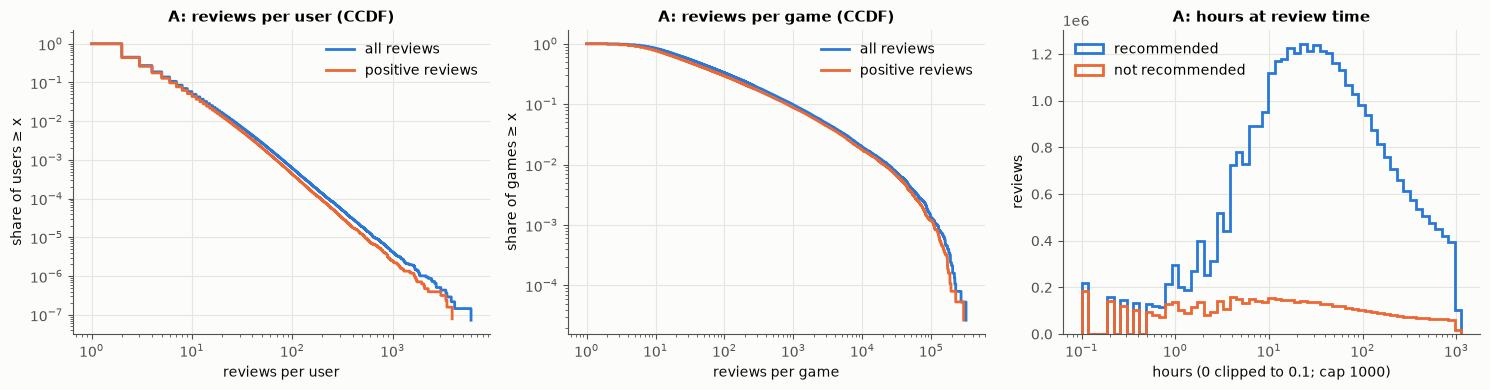

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ccdf(axes[0], u_cnt.values, "all reviews")
ccdf(axes[0], u_pos.values, "positive reviews")
axes[0].set(title="A: reviews per user (CCDF)", xlabel="reviews per user", ylabel="share of users ≥ x")
axes[0].legend()
ccdf(axes[1], i_cnt.values, "all reviews")
ccdf(axes[1], i_pos.values, "positive reviews")
axes[1].set(title="A: reviews per game (CCDF)", xlabel="reviews per game", ylabel="share of games ≥ x")
axes[1].legend()
bins = np.logspace(-1, 3.05, 60)
axes[2].hist(A_rec.hours[A_rec.is_recommended].clip(lower=0.1), bins=bins, histtype="step", lw=2, label="recommended")
axes[2].hist(A_rec.hours[~A_rec.is_recommended].clip(lower=0.1), bins=bins, histtype="step", lw=2, label="not recommended")
axes[2].set(xscale="log", title="A: hours at review time", xlabel="hours (0 clipped to 0.1; cap 1000)", ylabel="reviews")
axes[2].legend()
fig.tight_layout()
save_fig(fig, "fig01_A_interactions_hours")

,A_reviews,A_positive_rate,B_reviews_dated
year,,,
"2,010.0000",12201,0.9739,66.0000
"2,011.0000",71546,0.9650,532.0000
"2,012.0000",101726,0.9599,"1,215.0000"
"2,013.0000",335335,0.9307,"6,792.0000"
"2,014.0000",1143156,0.8796,"22,111.0000"
"2,015.0000",1477099,0.8347,"18,470.0000"
"2,016.0000",2226413,0.8349,NaN
"2,017.0000",2834442,0.8221,NaN
"2,018.0000",2845219,0.8132,NaN


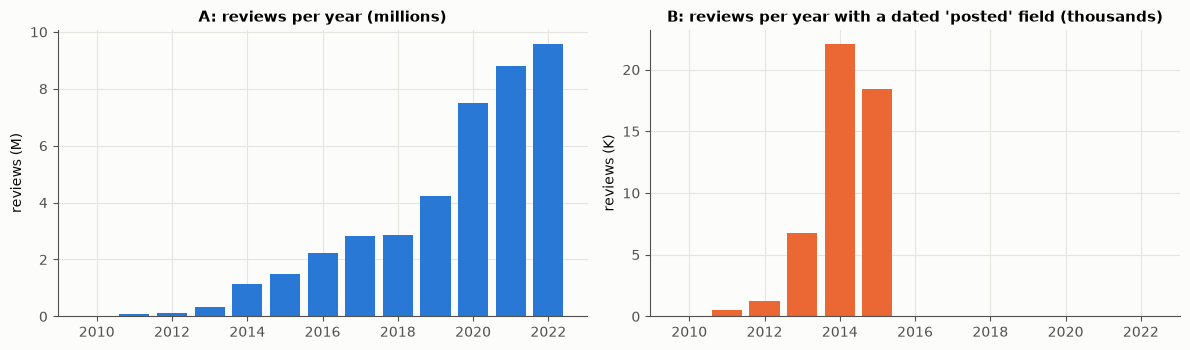

In [9]:
yearly = pd.DataFrame({
    "A_reviews": A_rec.groupby(A_rec.date.dt.year).size(),
    "A_positive_rate": A_rec.groupby(A_rec.date.dt.year).is_recommended.mean(),
    "B_reviews_dated": B_rev.groupby(B_rev.posted_date.dt.year).size(),
}).rename_axis("year")
save_table(yearly.reset_index(), "02_reviews_by_year")
rec("A_reviews_le_2015", int((A_rec.date <= "2015-12-31").sum()))
rec("B_review_dates", {"with_year": int(B_rev.posted_has_year.sum()), "without_year": int((~B_rev.posted_has_year).sum()),
                       "min": B_rev.posted_date.min(), "max": B_rev.posted_date.max()})

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharex=True)
axes[0].bar(yearly.index, yearly.A_reviews.fillna(0) / 1e6, color=BLUE, width=0.8)
axes[0].set(title="A: reviews per year (millions)", ylabel="reviews (M)")
axes[1].bar(yearly.index, yearly.B_reviews_dated.fillna(0) / 1e3, color=ORANGE, width=0.8)
axes[1].set(title="B: reviews per year with a dated 'posted' field (thousands)", ylabel="reviews (K)")
fig.tight_layout()
save_fig(fig, "fig02_reviews_by_year")
yearly

In [10]:
def kcore(df, ku, ki, max_iter=30):
    for _ in range(max_iter):
        before = len(df)
        df = df[df.groupby("app_id").user_id.transform("size") >= ki]
        df = df[df.groupby("user_id").app_id.transform("size") >= ku]
        if len(df) == before:
            break
    return df


lin_ids = set(A_games.app_id[A_games.linux])
pos_pairs = A_pos[["user_id", "app_id"]]
kc_rows = []
for ku, ki in [(1, 1), (2, 5), (3, 10), (5, 10), (5, 20), (10, 20)]:
    k = kcore(pos_pairs, ku, ki)
    nu, ni = k.user_id.nunique(), k.app_id.nunique()
    kc_rows.append({"min_user_pos": ku, "min_item_pos": ki, "users": nu, "items": ni, "interactions": len(k),
                    "density": len(k) / (nu * ni), "linux_items": len(set(k.app_id.unique()) & lin_ids),
                    "linux_interactions": int(k.app_id.isin(lin_ids).sum())})
kcore_tab = save_table(pd.DataFrame(kc_rows), "02_A_positive_kcore")
rec("A_positive_kcore", kc_rows)
kcore_tab

,min_user_pos,min_item_pos,users,items,interactions,density,linux_items,linux_interactions
0,1,1,12663134,37419,35304398,0.0001,6618,10428788
1,2,5,5547226,33148,28177261,0.0002,6142,8365174
2,3,10,3301339,27045,23644909,0.0003,5328,7079408
3,5,10,1621480,26064,17986052,0.0004,5195,5442255
4,5,20,1617467,19688,17882168,0.0006,4267,5424688
5,10,20,543517,17916,11021839,0.0011,3975,3391453


## 3. Linux 게임 분포
Linux 지원 여부는 **A의 `games.csv` `linux` 플래그**(공식 지원)를 기준으로 하고, C(2025-03)의 플래그와 일치도를 비교한다.

In [11]:
A_rec["is_linux"] = A_rec.app_id.isin(lin_ids)
lin_pos = A_rec[A_rec.is_linux & A_rec.is_recommended]
lin_pos_item = lin_pos.groupby("app_id").size().sort_values(ascending=False)
lin_pos_user = lin_pos.groupby("user_id").size()
lin_games = A_games[A_games.linux]

top_share = lambda s, f: float(s.iloc[: max(1, int(len(s) * f))].sum() / s.sum())
rec("A_linux", {
    "games_total": len(A_games), "linux_games": len(lin_games),
    "linux_games_pct": len(lin_games) / len(A_games) * 100,
    "linux_games_with_any_review": int(lin_games.app_id.isin(A_rec.app_id.unique()).sum()),
    "linux_games_with_ge10_positive": int((lin_pos_item >= 10).sum()),
    "linux_games_with_ge50_positive": int((lin_pos_item >= 50).sum()),
    "linux_games_released_le_2015": int((lin_games.date_release <= "2015-12-31").sum()),
    "reviews_on_linux": int(A_rec.is_linux.sum()),
    "reviews_on_linux_pct": float(A_rec.is_linux.mean() * 100),
    "positive_reviews_on_linux": len(lin_pos),
    "positive_rate_linux": float(A_rec.is_recommended[A_rec.is_linux].mean()),
    "positive_rate_non_linux": float(A_rec.is_recommended[~A_rec.is_linux].mean()),
    "users_with_ge1_linux_positive": len(lin_pos_user),
    "users_with_ge2_linux_positive": int((lin_pos_user >= 2).sum()),
    "users_with_ge5_linux_positive": int((lin_pos_user >= 5).sum()),
    "top1pct_linux_games_share_of_linux_positive": top_share(lin_pos_item, 0.01),
    "top10pct_linux_games_share_of_linux_positive": top_share(lin_pos_item, 0.10),
    "linux_positive_per_game": qtable(lin_pos_item),
    "linux_positive_reviews_le_2015": int((lin_pos.date <= "2015-12-31").sum()),
})
RESULTS["A_linux"]

{'games_total': 50872,
 'linux_games': 9041,
 'linux_games_pct': 17.772055354615507,
 'linux_games_with_any_review': 6630,
 'linux_games_with_ge10_positive': 5497,
 'linux_games_with_ge50_positive': 3299,
 'linux_games_released_le_2015': 2101,
 'reviews_on_linux': 11584426,
 'reviews_on_linux_pct': 28.148424215171623,
 'positive_reviews_on_linux': 10428788,
 'positive_rate_linux': 0.9002421009034025,
 'positive_rate_non_linux': 0.8412343735458415,
 'users_with_ge1_linux_positive': 5587235,
 'users_with_ge2_linux_positive': 1751635,
 'users_with_ge5_linux_positive': 335892,
 'top1pct_linux_games_share_of_linux_positive': 0.5115524450204568,
 'top10pct_linux_games_share_of_linux_positive': 0.913052312502661,
 'linux_positive_per_game': {'p25': 14.0,
  'p50': 49.0,
  'p75': 262.75,
  'p90': 1521.3000000000002,
  'p99': 36682.81999999999,
  'mean': 1575.8216983983077,
  'max': 294879.0},
 'linux_positive_reviews_le_2015': 1299646}

In [12]:
ac = A_games[["app_id", "title", "linux", "date_release"]].merge(
    C[["appid", "name", "linux", "release_date"]].rename(columns={"appid": "app_id"}), on="app_id", how="inner",
    suffixes=("_A", "_C"))
flag_ct = pd.crosstab(ac.linux_A, ac.linux_C, rownames=["A linux (2024)"], colnames=["C linux (2025-03)"])
save_table(flag_ct, "03_linux_flag_A_vs_C", index=True)
rec("linux_flag_A_vs_C", {"common_games": len(ac), "agree_pct": float((ac.linux_A == ac.linux_C).mean() * 100),
                          "A_true_C_false": int((ac.linux_A & ~ac.linux_C).sum()),
                          "A_false_C_true": int((~ac.linux_A & ac.linux_C).sum())})
flag_ct

C linux (2025-03),False,True
A linux (2024),,
False,29270,166
True,58,6382


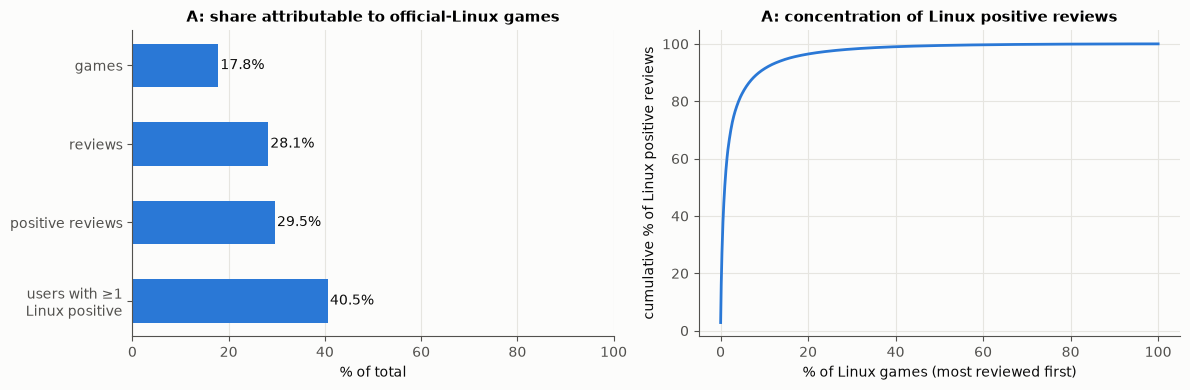

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
shares = pd.Series({
    "games": RESULTS["A_linux"]["linux_games_pct"],
    "reviews": RESULTS["A_linux"]["reviews_on_linux_pct"],
    "positive reviews": len(lin_pos) / int(A_rec.is_recommended.sum()) * 100,
    "users with ≥1\nLinux positive": len(lin_pos_user) / n_u * 100,
})
axes[0].barh(shares.index[::-1], shares.values[::-1], color=BLUE, height=0.55)
for y, v in enumerate(shares.values[::-1]):
    axes[0].text(v + 0.5, y, f"{v:.1f}%", va="center", color=INK)
axes[0].set(title="A: share attributable to official-Linux games", xlabel="% of total", xlim=(0, 100))
axes[0].grid(axis="y", visible=False)
cum = lin_pos_item.cumsum() / lin_pos_item.sum()
axes[1].plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values * 100, color=BLUE)
axes[1].set(title="A: concentration of Linux positive reviews", xlabel="% of Linux games (most reviewed first)",
            ylabel="cumulative % of Linux positive reviews")
fig.tight_layout()
save_fig(fig, "fig03_A_linux_share_concentration")

## 4. 데이터셋 결합 — Steam App ID 매칭
A `app_id` ↔ B `item_id`(보유) / B 리뷰 `item_id` / B `steam_games.id` ↔ C `appid`. 모두 Steam App ID(정수)로 정규화했다.
B의 `item_id`는 원본에서 문자열이며 모두 숫자로 변환되었다(변환 실패 0건, 1장 참고).

In [14]:
S = {
    "A_games": set(A_games.app_id), "A_rec_items": set(A_rec.app_id.unique()), "A_linux": lin_ids,
    "C": set(C.appid), "C_linux": set(C.appid[C.linux == True]),
    "B_owned_items": set(B_items.item_id.dropna()), "B_review_items": set(B_rev.item_id.dropna()),
    "B_pos_review_items": set(B_rev.item_id[B_rev.recommend].dropna()), "B_steam_games": set(B_sg.id.dropna()),
}
ov_rows = []
for b in ["B_owned_items", "B_review_items", "B_pos_review_items", "B_steam_games"]:
    s = S[b]
    ov_rows.append({"B_set": b, "n": len(s),
                    "in_A_games": len(s & S["A_games"]), "in_A_games_pct": len(s & S["A_games"]) / len(s) * 100,
                    "in_A_rec_items": len(s & S["A_rec_items"]),
                    "in_A_linux": len(s & S["A_linux"]),
                    "in_C": len(s & S["C"]), "in_C_pct": len(s & S["C"]) / len(s) * 100,
                    "in_A_or_C": len(s & (S["A_games"] | S["C"])),
                    "in_neither": len(s - S["A_games"] - S["C"])})
overlap = save_table(pd.DataFrame(ov_rows), "04_id_overlap")
rec("id_overlap", ov_rows)
rec("A_C_overlap", {"A_games": len(S["A_games"]), "C": len(S["C"]), "A_and_C": len(S["A_games"] & S["C"]),
                    "A_not_in_C": len(S["A_games"] - S["C"]), "A_linux_in_C": len(S["A_linux"] & S["C"])})
overlap

,B_set,n,in_A_games,in_A_games_pct,in_A_rec_items,in_A_linux,in_C,in_C_pct,in_A_or_C,in_neither
0,B_owned_items,10978,7990,72.7819,7807,2274,7856,71.5613,8775,2203
1,B_review_items,3682,2997,81.3960,2718,1023,2437,66.1869,3075,607
2,B_pos_review_items,3292,2706,82.1993,2462,943,2195,66.6768,2771,521
3,B_steam_games,32132,16214,50.4606,12598,4226,15112,47.0310,19493,12639


In [15]:
# 상호작용 가중 커버리지: 고유 게임 수가 아니라 B의 실제 기록(행) 중 A에 있는 게임의 비율
bi_in_A = B_items.item_id.isin(S["A_games"])
br_in_A = B_rev.item_id.isin(S["A_games"])
rec("B_interaction_coverage_by_A", {
    "owned_rows_in_A_pct": float(bi_in_A.mean() * 100),
    "owned_rows_played_in_A_pct": float(bi_in_A[B_items.playtime_forever > 0].mean() * 100),
    "playtime_weighted_in_A_pct": float(B_items.playtime_forever[bi_in_A].sum() / B_items.playtime_forever.sum() * 100),
    "review_rows_in_A_pct": float(br_in_A.mean() * 100),
    "positive_review_rows_in_A_pct": float(br_in_A[B_rev.recommend].mean() * 100),
    "positive_review_rows_in_A_linux_pct": float(B_rev.item_id[B_rev.recommend].isin(lin_ids).mean() * 100),
})
RESULTS["B_interaction_coverage_by_A"]

{'owned_rows_in_A_pct': 79.28929333159202,
 'owned_rows_played_in_A_pct': 83.66192364285658,
 'playtime_weighted_in_A_pct': 87.96028607440405,
 'review_rows_in_A_pct': 88.94865525672373,
 'positive_review_rows_in_A_pct': 90.24069521468184,
 'positive_review_rows_in_A_linux_pct': 54.544241800545045}

In [16]:
# 불일치 원인 분석: B 보유 게임 중 A에 없는 것
owners = B_items.drop_duplicates(["user_id", "item_id"]).groupby("item_id").agg(
    owners=("user_id", "size"), name=("item_name", "first"))
miss = owners[~owners.index.isin(S["A_games"])].copy()
patterns = {
    "server/SDK/tool": r"dedicated server|\bsdk\b|\btools?\b|editor|authoring|benchmark",
    "test/beta/demo": r"\btest\b|\bbeta\b|\bdemo\b|playtest|public test|\bpts\b",
    "soundtrack/video": r"soundtrack|\bost\b|artbook|movie|video|wallpaper",
    "dlc/pack": r"\bdlc\b|season pass|\bpack\b|expansion|bundle",
}
miss["reason_guess"] = "other"
for lab, pat in patterns.items():
    m = miss.reason_guess.eq("other") & miss.name.fillna("").str.contains(pat, case=False, regex=True)
    miss.loc[m, "reason_guess"] = lab
miss["in_C"] = miss.index.isin(S["C"])
miss["in_B_steam_games"] = miss.index.isin(S["B_steam_games"])
miss_summary = miss.groupby("reason_guess").agg(items=("owners", "size"), owner_rows=("owners", "sum"),
                                                in_C=("in_C", "sum"), in_B_steam_games=("in_B_steam_games", "sum"))
save_table(miss_summary.reset_index(), "04_B_owned_not_in_A_reasons")
rec("B_owned_not_in_A", {"items": len(miss), "owner_rows": int(miss.owners.sum()),
                         "median_owners": float(miss.owners.median()),
                         "median_owners_matched": float(owners.owners[owners.index.isin(S["A_games"])].median()),
                         "in_C": int(miss.in_C.sum()), "by_reason": miss_summary.reset_index().to_dict("records")})
save_table(miss.sort_values("owners", ascending=False).head(30).reset_index(), "04_B_owned_not_in_A_top30")
display(miss_summary)
miss.sort_values("owners", ascending=False).head(15)

,items,owner_rows,in_C,in_B_steam_games
reason_guess,,,,
dlc/pack,32,5564,4,22
other,2874,918001,779,1502
server/SDK/tool,18,12658,1,1
soundtrack/video,28,1031,0,14
test/beta/demo,36,117946,1,3


,owners,name,reason_guess,in_C,in_B_steam_games
item_id,,,,,
205790,49136,Dota 2 Test,test/beta/demo,False,False
223530,36661,Left 4 Dead 2 Beta,test/beta/demo,False,False
72850,22038,The Elder Scrolls V: Skyrim,other,True,False
208090,16309,Loadout,other,False,True
232210,15740,Patch testing for Chivalry,other,False,False
219540,14922,Arma 2: Operation Arrowhead Beta (Obsolete),test/beta/demo,False,False
33910,14500,Arma 2,other,False,False
243870,14449,Tom Clancy's Ghost Recon Phantoms - NA,other,False,False
35420,13834,Killing Floor Mod: Defence Alliance 2,other,False,True


In [17]:
# 메타데이터 중복·일치도: 공통 App ID의 제목 일치(정규화 후), 출시일 일치
norm = lambda s: s.fillna("").str.lower().str.replace(r"[^0-9a-z]+", "", regex=True)
ac["title_match"] = norm(ac.title) == norm(ac.name)
ac["date_match"] = pd.to_datetime(ac.date_release).dt.date.astype(str) == ac.release_date.astype(str)
ab = A_games[["app_id", "title"]].merge(B_sg.dropna(subset=["id"]).drop_duplicates("id")[["id", "app_name"]]
                                        .rename(columns={"id": "app_id"}), on="app_id")
ab["title_match"] = norm(ab.title) == norm(ab.app_name)
rec("metadata_consistency", {"A_vs_C_title_match_pct": float(ac.title_match.mean() * 100),
                             "A_vs_C_release_date_match_pct": float(ac.date_match.mean() * 100),
                             "A_vs_B_steam_games_common": len(ab),
                             "A_vs_B_steam_games_title_match_pct": float(ab.title_match.mean() * 100)})
RESULTS["metadata_consistency"]

{'A_vs_C_title_match_pct': 98.76240383543316,
 'A_vs_C_release_date_match_pct': 97.2154086297246,
 'A_vs_B_steam_games_common': 16214,
 'A_vs_B_steam_games_title_match_pct': 96.23165165906006}

In [18]:
# 콘텐츠 기반 모델용 텍스트 피처 가용성 (Linux 게임 기준)
lm = lin_games[["app_id"]].merge(A_meta, on="app_id", how="left").merge(
    C[["appid", "tags", "genres", "short_description"]].rename(columns={"appid": "app_id", "tags": "C_tags"}),
    on="app_id", how="left")
has_A_tags = lm.tags.map(lambda t: t is not None and len(t) > 0)
has_A_desc = lm.description.fillna("").str.strip().ne("")
has_C_tags = ~lm.C_tags.fillna("{}").isin(["{}", "[]", ""])
has_C_genres = ~lm.genres.fillna("[]").isin(["[]", ""])
rec("linux_content_features", {
    "linux_games": len(lm), "A_tags_pct": float(has_A_tags.mean() * 100), "A_desc_pct": float(has_A_desc.mean() * 100),
    "C_tags_pct": float(has_C_tags.mean() * 100), "C_genres_pct": float(has_C_genres.mean() * 100),
    "A_or_C_tags_pct": float((has_A_tags | has_C_tags).mean() * 100),
    "no_text_at_all": int((~has_A_tags & ~has_A_desc & ~has_C_tags & ~has_C_genres).sum()),
    "A_tags_per_game_median": float(lm.tags.map(lambda t: 0 if t is None else len(t)).median()),
})
RESULTS["linux_content_features"]

{'linux_games': 9041,
 'A_tags_pct': 97.96482689967924,
 'A_desc_pct': 76.6397522397965,
 'C_tags_pct': 68.24466320097335,
 'C_genres_pct': 71.15363344762747,
 'A_or_C_tags_pct': 99.3584780444641,
 'no_text_at_all': 56,
 'A_tags_per_game_median': 12.0}

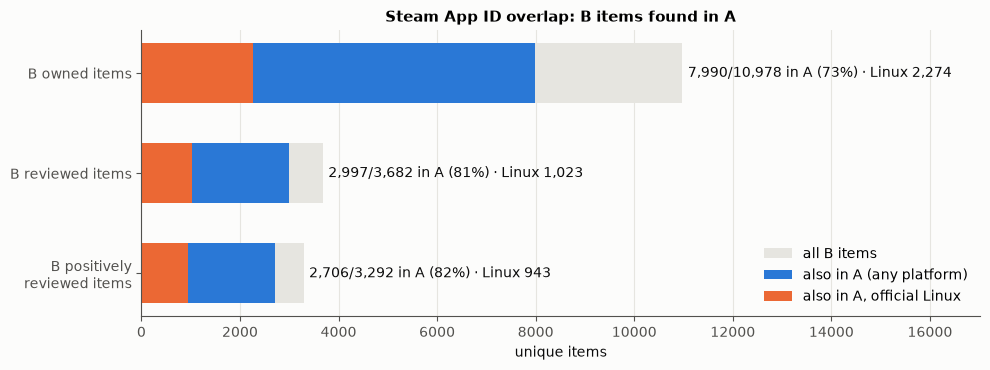

In [19]:
fig, ax = plt.subplots(figsize=(10, 3.8))
labels = ["B owned items", "B reviewed items", "B positively\nreviewed items"]
keys = ["B_owned_items", "B_review_items", "B_pos_review_items"]
tot = np.array([len(S[k]) for k in keys])
inA = np.array([len(S[k] & S["A_games"]) for k in keys])
inL = np.array([len(S[k] & S["A_linux"]) for k in keys])
y = np.arange(len(keys))[::-1]
ax.barh(y, tot, color=GRID, height=0.6, label="all B items")
ax.barh(y, inA, color=BLUE, height=0.6, label="also in A (any platform)")
ax.barh(y, inL, color=ORANGE, height=0.6, label="also in A, official Linux")
for yi, t, a, l in zip(y, tot, inA, inL):
    ax.text(t + tot.max() * 0.01, yi, f"{a:,}/{t:,} in A ({a / t:.0%}) · Linux {l:,}", va="center", color=INK)
ax.set_yticks(y, labels)
ax.set(title="Steam App ID overlap: B items found in A", xlabel="unique items", xlim=(0, tot.max() * 1.55))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
fig.tight_layout()
save_fig(fig, "fig04_id_overlap")

## 5. 외부 평가 가능성 (A로 학습한 모델에 B 사용자 이력 입력)

**사용자별 평가 방법**
- 정답 게임 (`target`): B `australian_user_reviews`의 `recommend=True` 리뷰 중 **A의 공식 Linux 게임**인 것.
- 입력 이력 (`input`): 같은 B 사용자(B 내부 `user_id`로만 연결)의 `australian_users_items` 보유 게임 중 A 아이템 공간에 있는 것.
- **누출 방지**: 입력에서 해당 사용자가 리뷰한 게임(긍정·부정 모두)을 제거한다. 리뷰된 게임은 보유 목록에도 대부분 있으므로(아래 확인) 제거하지 않으면 정답이 입력에 그대로 노출된다.
- 추천 후보: A의 Linux 게임에서 입력 게임을 제외한 것. 보유·플레이(입력)와 긍정 리뷰(정답)는 서로 다른 신호로 취급한다.

B는 A의 학습 데이터에 사용하지 않는다(모델 재학습 없음, 신규 사용자 추론만).

In [20]:
# B 정리: 중복 프로필은 user_id별 첫 줄만 사용(1-1에서 동일성 확인), 리뷰는 user-item 중복 제거·라벨 충돌 제외
first_line = B_prof.groupby("user_id").line_no.min()
Bi = (B_items[B_items.line_no.isin(first_line.values)]
      .drop_duplicates(["user_id", "item_id"])[["user_id", "item_id", "playtime_forever"]])
conf_pairs = conflict[conflict].reset_index()[["user_id", "item_id"]]
Br = (B_rev.dropna(subset=["item_id"]).drop_duplicates(["user_id", "item_id", "recommend"])
      .merge(conf_pairs.assign(_c=1), on=["user_id", "item_id"], how="left"))
Br = Br[Br._c.isna()].drop(columns="_c")

owned_pairs = set(zip(Bi.user_id, Bi.item_id))
Br["owned"] = [(u, i) in owned_pairs for u, i in zip(Br.user_id, Br.item_id)]
rec("B_review_vs_ownership", {
    "review_users": Br.user_id.nunique(),
    "review_users_with_item_profile": int(Br.user_id.drop_duplicates().isin(Bi.user_id.unique()).sum()),
    "reviewed_items_also_owned_pct": float(Br.owned.mean() * 100),
    "positive_reviewed_items_also_owned_pct": float(Br.owned[Br.recommend].mean() * 100),
    "B_positive_rate": float(Br.recommend.mean()),
})
RESULTS["B_review_vs_ownership"]

{'review_users': 25458,
 'review_users_with_item_profile': 22613,
 'reviewed_items_also_owned_pct': 75.62081771662302,
 'positive_reviewed_items_also_owned_pct': 75.96726766230752,
 'B_positive_rate': 0.8846673854631959}

In [21]:
A_items = S["A_rec_items"]
cf_items = set(i_pos.index[i_pos >= 10])  # 협업 필터링에서 이웃 계산이 의미 있는 최소 기준(긍정 10명 이상)
L_all = lin_ids & A_items
L_cf = lin_ids & cf_items
rec("candidate_sets", {"A_linux_with_reviews": len(L_all), "A_linux_ge10_positive": len(L_cf),
                       "A_items_ge10_positive": len(cf_items)})

reviewed = Br.groupby("user_id").item_id.agg(set)
targets_all = Br[Br.recommend & Br.item_id.isin(L_all)].groupby("user_id").item_id.agg(set)

Bi_A = Bi[Bi.item_id.isin(A_items)]
inp_owned = Bi_A.groupby("user_id").item_id.agg(set)
inp_played = Bi_A[Bi_A.playtime_forever > 0].groupby("user_id").item_id.agg(set)

users = targets_all.index
ev = pd.DataFrame(index=users)
ev["targets"] = targets_all
ev["targets_cf"] = ev.targets.map(lambda t: t & L_cf)
rv = reviewed.reindex(users)
ev["input_owned"] = [(inp_owned.get(u, set()) - rv[u]) for u in users]
ev["input_played"] = [(inp_played.get(u, set()) - rv[u]) for u in users]
ev["input_owned_cf"] = ev.input_owned.map(lambda s: s & cf_items)
for c in ["targets", "targets_cf", "input_owned", "input_played", "input_owned_cf"]:
    ev["n_" + c] = ev[c].map(len)
assert all(not (t & i) for t, i in zip(ev.targets, ev.input_owned)), "leakage: target in input"

elig_rows = []
for inp in ["input_owned", "input_played", "input_owned_cf"]:
    for tgt in ["targets", "targets_cf"]:
        for k in [1, 2, 3, 5, 10, 20]:
            m = (ev["n_" + tgt] >= 1) & (ev["n_" + inp] >= k)
            elig_rows.append({"input": inp, "target": tgt, "min_input_items": k, "users": int(m.sum()),
                              "target_pairs": int(ev.loc[m, "n_" + tgt].sum()),
                              "unique_target_items": len(set().union(*ev.loc[m, tgt])) if m.any() else 0})
elig = save_table(pd.DataFrame(elig_rows), "05_external_test_eligibility")
rec("external_test_eligibility", elig_rows)
rec("external_test_main", {
    "users_with_linux_positive_target": int((ev.n_targets >= 1).sum()),
    "target_pairs": int(ev.n_targets.sum()), "unique_target_items": len(set().union(*ev.targets)),
    "targets_per_user": qtable(ev.n_targets),
    "users_with_ge2_targets": int((ev.n_targets >= 2).sum()),
    "input_owned_per_user": qtable(ev.n_input_owned),
    "eligible_users_k5_owned": int(((ev.n_targets >= 1) & (ev.n_input_owned >= 5)).sum()),
    "target_pairs_k5_owned": int(ev.n_targets[ev.n_input_owned >= 5].sum()),
    "target_pairs_that_are_cf_items_pct": float(ev.n_targets_cf.sum() / ev.n_targets.sum() * 100),
})
elig.pivot_table(index=["input", "min_input_items"], columns="target", values="users")

target                             targets  targets_cf
input          min_input_items                        
input_owned    1               15,676.0000 15,676.0000
               2               15,609.0000 15,609.0000
               3               15,519.0000 15,519.0000
               5               15,294.0000 15,294.0000
               10              14,697.0000 14,697.0000
               20              13,076.0000 13,076.0000
input_owned_cf 1               15,676.0000 15,676.0000
               2               15,609.0000 15,609.0000
               3               15,518.0000 15,518.0000
               5               15,294.0000 15,294.0000
               10              14,694.0000 14,694.0000
               20              13,071.0000 13,071.0000
input_played   1               15,629.0000 15,629.0000
               2               15,507.0000 15,507.0000
               3               15,357.0000 15,357.0000
               5               15,067.0000 15,067.0000
               10              14,147.0000 14,147.0000
               20              11,987.0000 11,987.0000

In [22]:
# 대안 프로토콜(리뷰만 사용): B 리뷰 간 leave-one-out — 긍정 리뷰 ≥2건(A 아이템) 중 Linux 1건 이상
pos_A = Br[Br.recommend & Br.item_id.isin(A_items)].groupby("user_id").item_id.agg(set)
lo = pos_A[pos_A.map(len) >= 2]
rec("review_only_protocol", {"users_ge2_positive_in_A": len(lo),
                             "of_which_ge1_linux": int(lo.map(lambda s: len(s & L_all) >= 1).sum())})
RESULTS["review_only_protocol"]

{'users_ge2_positive_in_A': 9771, 'of_which_ge1_linux': 8771}

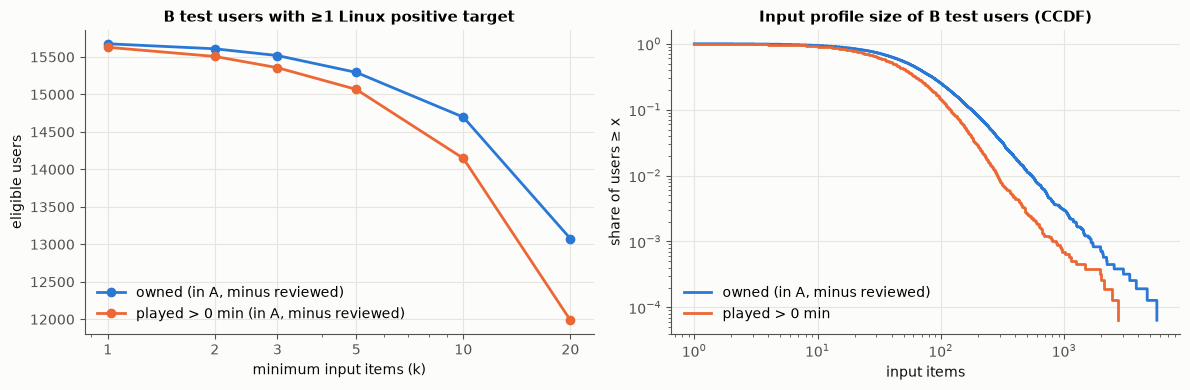

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# input_owned_cf는 input_owned와 거의 같아(입력 게임의 99.6%가 CF 아이템) 선이 겹치므로 그리지 않는다.
for inp, col, lab in [("input_owned", BLUE, "owned (in A, minus reviewed)"),
                      ("input_played", ORANGE, "played > 0 min (in A, minus reviewed)")]:
    d = elig[(elig.input == inp) & (elig.target == "targets")]
    axes[0].plot(d.min_input_items, d.users, marker="o", ms=6, color=col, label=lab)
axes[0].set(xscale="log", title="B test users with ≥1 Linux positive target", xlabel="minimum input items (k)",
            ylabel="eligible users")
axes[0].set_xticks([1, 2, 3, 5, 10, 20], ["1", "2", "3", "5", "10", "20"])
axes[0].legend()
ccdf(axes[1], ev.n_input_owned[ev.n_input_owned > 0].values, "owned (in A, minus reviewed)", BLUE)
ccdf(axes[1], ev.n_input_played[ev.n_input_played > 0].values, "played > 0 min", ORANGE)
axes[1].set(title="Input profile size of B test users (CCDF)", xlabel="input items", ylabel="share of users ≥ x")
axes[1].legend()
fig.tight_layout()
save_fig(fig, "fig05_external_test_eligibility")

### 5-1. 인기도·시점 차이와 인기순 추천의 평가 결과
인기순 추천으로 **평가 방법이 예상대로 동작하는지** 확인한다. 인기도는 A의 Linux 긍정 리뷰 수만 사용한다(B 정보 미사용).

{'linux_items_compared': 6618,
 'spearman_A_pos_vs_B_pos': 0.4582638478234919,
 'spearman_A_pos_vs_B_owners': 0.4244909008442292,
 'spearman_A_pos_le2015_vs_B_pos': 0.6502089518851554}

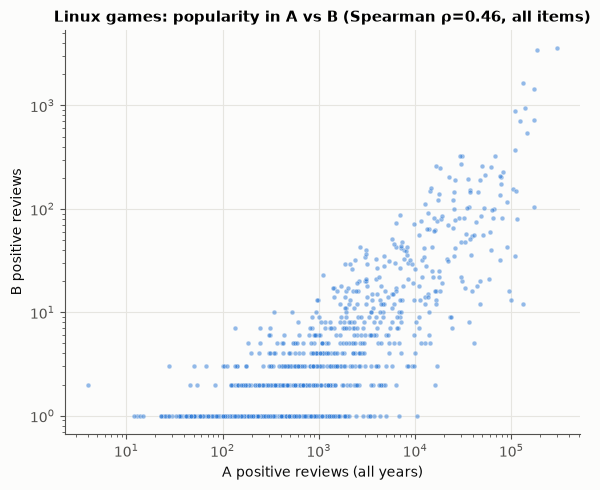

In [24]:
pop_A = lin_pos_item  # A Linux 긍정 리뷰 수
B_pos_cnt = Br[Br.recommend & Br.item_id.isin(L_all)].groupby("item_id").size()
B_own_cnt = Bi[Bi.item_id.isin(L_all)].groupby("item_id").size()
common = pd.DataFrame({"A_pos": pop_A, "B_pos": B_pos_cnt, "B_owners": B_own_cnt}).dropna(subset=["A_pos"]).fillna(0)
rho_pos = stats.spearmanr(common.A_pos, common.B_pos).statistic
rho_own = stats.spearmanr(common.A_pos, common.B_owners).statistic
A_pre = A_rec[(A_rec.date <= "2015-12-31") & A_rec.is_linux & A_rec.is_recommended].groupby("app_id").size()
rho_pre = stats.spearmanr(A_pre.reindex(common.index, fill_value=0), common.B_pos).statistic
rec("popularity_shift", {"linux_items_compared": len(common), "spearman_A_pos_vs_B_pos": float(rho_pos),
                         "spearman_A_pos_vs_B_owners": float(rho_own),
                         "spearman_A_pos_le2015_vs_B_pos": float(rho_pre)})

fig, ax = plt.subplots(figsize=(6, 5))
c2 = common[common.B_pos > 0]
ax.scatter(c2.A_pos, c2.B_pos, s=12, alpha=0.5, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
ax.set(xscale="log", yscale="log", xlabel="A positive reviews (all years)", ylabel="B positive reviews",
       title=f"Linux games: popularity in A vs B (Spearman ρ={rho_pos:.2f}, all items)")
fig.tight_layout()
save_fig(fig, "fig06_popularity_A_vs_B")
RESULTS["popularity_shift"]

In [25]:
def eval_topk(ev_df, scores, k=10, input_col="input_owned", target_col="targets"):
    order = scores.sort_values(ascending=False).index.to_numpy()
    rec_, ndcg_ = [], []
    disc = 1 / np.log2(np.arange(2, k + 2))
    for inp, tgt in zip(ev_df[input_col], ev_df[target_col]):
        top = [i for i in order[: k + len(inp)] if i not in inp][:k]
        hits = np.array([i in tgt for i in top], dtype=float)
        rec_.append(hits.sum() / len(tgt))
        ndcg_.append((hits * disc[: len(hits)]).sum() / disc[: min(len(tgt), k)].sum())
    return float(np.mean(rec_)), float(np.mean(ndcg_))


sub = ev[(ev.n_targets >= 1) & (ev.n_input_owned >= 5)]
released_le2015 = set(A_games.app_id[A_games.date_release <= "2015-12-31"])
pop_le2015 = pop_A[pop_A.index.isin(released_le2015)]
base = {}
for name, sc in [("pop_A_all_linux", pop_A), ("pop_A_linux_released_le2015", pop_le2015),
                 ("pop_A_reviews_le2015", A_pre)]:
    r, nd = eval_topk(sub, sc)
    base[name] = {"recall@10": r, "ndcg@10": nd, "candidates": len(sc)}
base["random_expected_recall@10"] = {"recall@10": 10 / len(L_all), "candidates": len(L_all)}
rec("popularity_baseline_sanity", {"users": len(sub), **base})
RESULTS["popularity_baseline_sanity"]

{'users': 15294,
 'pop_A_all_linux': {'recall@10': 0.538638142149323,
  'ndcg@10': 0.3730987564470092,
  'candidates': 6618},
 'pop_A_linux_released_le2015': {'recall@10': 0.546602516600555,
  'ndcg@10': 0.376927460932913,
  'candidates': 1521},
 'pop_A_reviews_le2015': {'recall@10': 0.585995000633094,
  'ndcg@10': 0.38368204873876627,
  'candidates': 1649},
 'random_expected_recall@10': {'recall@10': 0.0015082956259426848,
  'candidates': 6630}}

### 5-2. 정답 집중도와 인기 상위 게임을 제외한 평가
인기순 기준선이 높은 이유를 확인한다. 정답이 소수 대형 게임에 몰려 있으면 개인화 모델이 기준선을 넘기 어렵고,
평가가 사실상 "인기 게임 맞히기"가 된다. A의 인기 상위 50개 Linux 게임을 정답에서 제외한 성능도 함께 확인한다.

In [26]:
tgt_cnt = pd.Series([i for s in sub.targets for i in s]).value_counts()
top_tgt = pd.DataFrame({"target_pairs": tgt_cnt.head(15), "share": tgt_cnt.head(15) / tgt_cnt.sum(),
                        "A_linux_pos_rank": pop_A.rank(ascending=False).reindex(tgt_cnt.head(15).index),
                        "title": A_games.set_index("app_id").title.reindex(tgt_cnt.head(15).index)})
save_table(top_tgt.rename_axis("app_id").reset_index(), "05_top_target_items")

HEAD_N = 50
head = set(pop_A.index[:HEAD_N])
sub_lt = sub.assign(targets=sub.targets.map(lambda s: s - head))
sub_lt = sub_lt[sub_lt.targets.map(len) > 0]
r_full, nd_full = eval_topk(sub_lt, pop_A)                       # 후보 전체, 롱테일 정답
r_tail, nd_tail = eval_topk(sub_lt, pop_A[~pop_A.index.isin(head)])  # head를 후보에서도 제외
rec("target_concentration", {
    "top3_items_share": float(tgt_cnt.head(3).sum() / tgt_cnt.sum()),
    "top10_items_share": float(tgt_cnt.head(10).sum() / tgt_cnt.sum()),
    "targets_in_A_top50_linux_share": float(tgt_cnt[tgt_cnt.index.isin(head)].sum() / tgt_cnt.sum()),
    "longtail_users": len(sub_lt), "longtail_target_pairs": int(sub_lt.targets.map(len).sum()),
    "longtail_unique_items": len(set().union(*sub_lt.targets)),
    "pop_recall@10_longtail_targets_full_candidates": r_full,
    "pop_recall@10_longtail_targets_head_excluded": r_tail, "pop_ndcg@10_longtail_head_excluded": nd_tail,
})
display(top_tgt)
RESULTS["target_concentration"]

,target_pairs,share,A_linux_pos_rank,title
440,3072,0.1244,1.0000,Team Fortress 2
730,3048,0.1234,2.0000,Counter-Strike: Global Offensive
4000,1482,0.0600,8.0000,Garry's Mod
570,1243,0.0503,4.0000,Dota 2
304930,833,0.0337,7.0000,Unturned
218620,797,0.0323,16.0000,PAYDAY 2
550,631,0.0255,3.0000,Left 4 Dead 2
105600,628,0.0254,11.0000,Terraria
49520,474,0.0192,6.0000,Borderlands 2
620,323,0.0131,14.0000,Portal 2


{'top3_items_share': 0.3077234455958549,
 'top10_items_share': 0.5072457901554405,
 'targets_in_A_top50_linux_share': 0.6403416450777202,
 'longtail_users': 6533,
 'longtail_target_pairs': 8885,
 'longtail_unique_items': 786,
 'pop_recall@10_longtail_targets_full_candidates': 0.0,
 'pop_recall@10_longtail_targets_head_excluded': 0.03202860204237826,
 'pop_ndcg@10_longtail_head_excluded': 0.014330966630115786}

## 6. 신규 사용자에 대한 협업 필터링 적용 가능성
- A와 B의 사용자 ID를 연결할 수 없어 A에서 학습한 사용자 벡터를 B에 직접 적용할 수 없다. 같은 실제 사용자가 두 자료에 있는지는 확인할 수 없다.
- Item-KNN은 A에서 학습한 게임 간 유사도를 사용하므로 B 사용자의 입력 이력으로 추천할 수 있다. 여기서는 입력 게임에 A의 긍정 리뷰가 10개 이상 있는 조건도 확인한다.
- implicit ALS는 학습한 게임 벡터를 유지한 채 새 사용자의 입력 이력으로 사용자 벡터를 계산해야 한다. 이를 fold-in이라고 한다.

In [27]:
lin_cf_tgt = ev.n_targets_cf.sum() / ev.n_targets.sum()
rec("new_user_cf", {
    "A_users_lt5_positive_pct": float((u_pos.reindex(u_cnt.index, fill_value=0) < 5).mean() * 100),
    "B_test_users_with_0_cf_input": int((ev.n_input_owned_cf == 0).sum()),
    "B_test_users_with_ge5_cf_input": int((ev.n_input_owned_cf >= 5).sum()),
    "B_test_users": len(ev),
    "B_input_items_cf_share_pct": float(ev.n_input_owned_cf.sum() / max(ev.n_input_owned.sum(), 1) * 100),
    "B_targets_reachable_by_itemknn_pct": float(lin_cf_tgt * 100),
    "B_input_cf_per_user": qtable(ev.n_input_owned_cf),
})
RESULTS["new_user_cf"]

{'A_users_lt5_positive_pct': 88.21523077435486,
 'B_test_users_with_0_cf_input': 1900,
 'B_test_users_with_ge5_cf_input': 15294,
 'B_test_users': 17576,
 'B_input_items_cf_share_pct': 99.59271269013269,
 'B_targets_reachable_by_itemknn_pct': 99.99284487693188,
 'B_input_cf_per_user': {'p25': 19.0,
  'p50': 46.0,
  'p75': 91.0,
  'p90': 163.0,
  'p99': 497.75,
  'mean': 75.9625056895767,
  'max': 5275.0}}

## 7. 결과 저장

In [28]:
(REP / "eda_metrics.json").write_text(json.dumps(RESULTS, indent=2, ensure_ascii=False, default=str), "utf-8")
print("saved", REP / "eda_metrics.json", "keys:", len(RESULTS))
print(sorted(p.name for p in FIG.glob("*.png")))

saved C:\dev\game_recommendation\EDA\reports\eda_metrics.json keys: 27
['fig01_A_interactions_hours.png', 'fig02_reviews_by_year.png', 'fig03_A_linux_share_concentration.png', 'fig04_id_overlap.png', 'fig05_external_test_eligibility.png', 'fig06_popularity_A_vs_B.png']
